In [ ]:
# import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# load dataset
data = pd.read_csv('housing.csv')
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
# understand the dataset
data.shape

(20640, 10)

In [ ]:
# check columns names
data.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

In [ ]:
# dataset cleaning
data.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [ ]:
# display only missing columns
data.isnull().sum()[data.isnull().sum() > 0]

,0


In [ ]:
# replace null value with mean value
data['total_bedrooms'].fillna(data['total_bedrooms'].mean(), inplace=True)

/tmp/ipykernel_1351/3085271473.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['total_bedrooms'].fillna(data['total_bedrooms'].mean(), inplace=True)


In [ ]:
# feature selection
features = ["housing_median_age","total_rooms","total_bedrooms","population","households","median_income"]

x = data[features]
y = data["median_house_value"]

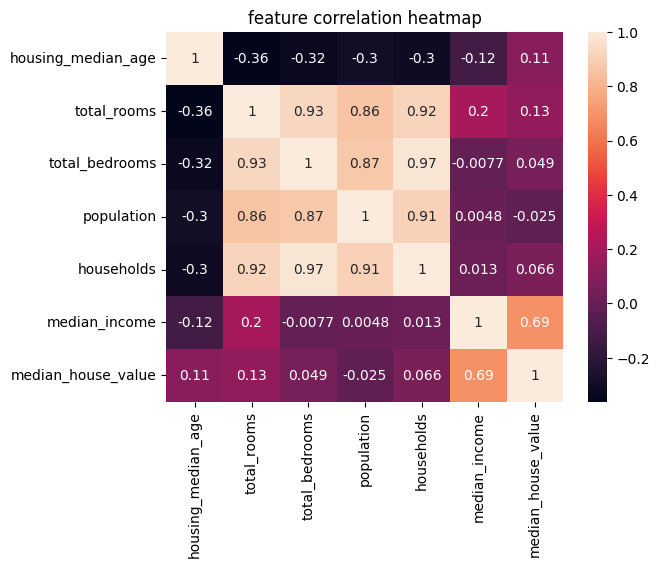

In [ ]:
# EDA
# heatmap analysis -->
plt.figure()
sns.heatmap(data[features + ["median_house_value"]].corr(),annot = True)
plt.title("feature correlation heatmap")
plt.show()

median_house_value = target
corelation btw traget and independent variable

median_house_value ---- median_income
 1. median_income = Median income of people living in a particular area.
 2. median_house_value = Median value of houses in that area.

median_house_value ---- households
 1. households = Number of households (groups of people living together) in a particular area.
 2. median_house_value = Median house value in that area.





In [ ]:
# Train test split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
# model training
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
# model coefficients
print("coefficients",model.coef_)
print("intercept", model.intercept_)


coefficients [ 1.89699824e+03 -2.00028194e+01  1.01942122e+02 -3.56517934e+01
  1.27029956e+02  4.79589084e+04]
intercept -47897.58543802879


In [ ]:
# model predictions
y_pred = model.predict(X_test)
y_pred[:5]

array([100859.76709752, 144764.5517973 , 271494.98514251, 255417.00090576,
       219523.28998766])

In [ ]:
# evaluate model performance
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("mse",mse)
print('rmse',rmse)
print("r2",r2)

mse 5963976459.533631
rmse 77226.78589410303
r2 0.5448767095949154


score model performane
0.50  week
0.60  ok
0.70  good
0.80  very good
0.90  excellent

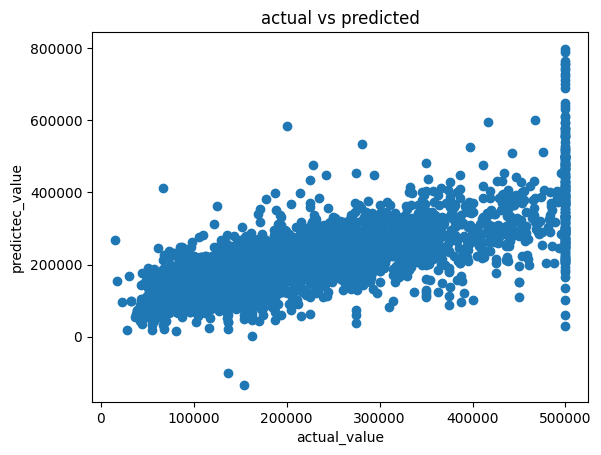

In [ ]:
# Actual vs Predicted visualization
plt.figure()
plt.scatter(y_test, y_pred)
plt.xlabel("actual_value")
plt.ylabel("predictec_value")
plt.title("actual vs predicted")
plt.show()
# this model is weel because of that point are more clumsy